# 16강 실습: HuggingFace 데이터 활용과 KLUE-NLI 읽기

오늘은 HuggingFace Hub의 데이터셋을 코드로 불러와 표로 바꾼다. 쓰는 데이터는 KLUE의 자연어 추론 과제(`klue/klue`, 설정 `nli`)다. 전제 하나에 작성자가 함의, 중립, 모순 가설을 하나씩 쓰게 해서 만들었다.

읽어 볼 물음은 이것이다. **모순 문장을 쓰라고 하면 사람은 어떻게 쓸까?** 부정 표현을 세어 보면 훈련 세트의 모순 가설에는 29.4%, 검증 세트에는 14.6%가 나온다. 왜 다른지는 카드에 없고 논문(Park et al. 2021, arXiv:2105.09680, 21쪽)에 있다.

터미널에서 먼저 `pip install datasets`를 한다.

## 0. 준비

7강의 pandas와 seaborn, matplotlib을 불러오고, `load_dataset`을 더한다. 10강의 `data/nsmc/ratings.txt`와 `kiwipiepy`를 오늘 다시 쓴다.

`IProgress not found` 경고가 나와도 된다. 진행 막대를 그리는 위젯이 없다는 말이고, 결과와는 상관없다.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

sns.set_theme(style='whitegrid', font='NanumGothic')


## 1. 불러오기

- `'klue/klue'`: 저장소 이름. GitHub처럼 올린 이/데이터셋이다.
- `'nli'`: 설정. Hub 화면의 Subset이다. KLUE에는 8개가 있다.
- `nli`: 분할 이름을 열쇠로 갖는 사전(`DatasetDict`, 11강의 `dict`처럼 쓴다).

`unauthenticated requests` 경고가 나와도 된다. 공개 데이터는 로그인 없이 받는다. 내려받은 파일은 저장소 밖 `~/.cache/huggingface/`에 있어 `git`에 잡히지 않는다. 다시 부르면 내려받지 않고 거기서 읽는다.

In [2]:
nli = load_dataset('klue/klue', 'nli')
print(nli.keys())
print(nli['train'])


dict_keys(['train', 'validation'])
Dataset({
    features: ['guid', 'source', 'premise', 'hypothesis', 'label'],
    num_rows: 24998
})


한 행은 `dict`다. `label`은 수로 적혀 있다.

In [3]:
for key, value in nli['train'][0].items():
    print(key, value)


guid klue-nli-v1_train_00000
source NSMC
premise 힛걸 진심 최고다 그 어떤 히어로보다 멋지다
hypothesis 힛걸 진심 최고로 멋지다.
label 0


- `features`: 각 열의 자료형. `label`은 이름표가 달린 범주다(`ClassLabel`).
- `int2str`: 번호를 이름으로 바꾸는 함수. 괄호 없이 함수 자체를 `names`에 담았다.

번호는 데이터셋마다 다르게 매겨진다. 0이 무엇인지 짐작하지 말고 꺼내어 확인한다.

In [4]:
names = nli['train'].features['label'].int2str
print(names(0), names(1), names(2))


entailment neutral contradiction


분할 하나만 부르면 `DatasetDict`가 아니라 `Dataset`이 온다.

논문의 전체는 30,998쌍이다(훈련 24,998, 검증 3,000, 시험 3,000). Hub에는 시험 세트가 없어 27,998쌍이다. 논문의 dev가 여기의 `validation`이다.

In [5]:
dev = load_dataset('klue/klue', 'nli', split='validation')
print(type(dev).__name__, dev.num_rows)


Dataset 3000


**버전 못 박기.** Hub의 저장소는 git 저장소다(2강). `revision`을 적지 않으면 그날의 최신 커밋을 받으니, 고쳐지면 같은 코드가 다른 데이터를 받는다. 이 해시는 [Files and versions]의 커밋 기록에서 볼 수 있다.

(슬라이드에서 본 `load_dataset('e9t/nsmc')`는 `Dataset scripts are no longer supported` 오류가 나므로 여기에 넣지 않았다. 그런 데이터는 10강처럼 원본에서 받는다.)

In [6]:
nli = load_dataset('klue/klue', 'nli',
                   revision='349481ec73fff722f88e0453ca05c77a447d967c')
print(nli['train'].num_rows, nli['validation'].num_rows)


24998 3000


## 2. 설치가 바꾼 것

12강의 `\b`를 다시 부른다. 12강이라면 `[1, 0]`이어야 하는데 **오류도 경고도 없이** 0이 나온다. 12강 말뭉치의 '완전' 8,636번도 0이 된다.

`pip install datasets`가 `pyarrow`를 함께 설치했기 때문이다. pandas 3은 `pyarrow`가 있으면 `str.count`, `str.contains`, `str.replace`의 정규표현식을 그쪽 엔진으로 돌리고, 거기서 `\b`와 `\w`는 영문자와 숫자만 글자로 친다. 한글은 글자가 아닌 셈이다.

In [7]:
s = pd.Series(['완전 좋아', '이건 완전히 달라'])
print(s.dtype.storage, s.str.count(r'\b완전\b').tolist())


pyarrow [0, 0]


이 줄로 되돌린다. 문자열 열을 **만들기 전에** 둔다.

이 Codespace의 다른 노트북도 마찬가지다. 12·13강 노트북을 다시 돌리거나 기말프로젝트에서 `\b`, `\w`를 쓴다면 첫 셀에 이 줄을 넣는다.

In [8]:
pd.set_option('mode.string_storage', 'python')
s = pd.Series(['완전 좋아', '이건 완전히 달라'])
print(s.dtype.storage, s.str.count(r'\b완전\b').tolist())


python [1, 0]


환경도 남긴다. 데이터도 코드도 그대로인데 설치한 패키지 때문에 수가 바뀌었다. 남겨야 할 버전에는 데이터의 버전뿐 아니라 패키지의 버전도 들어간다.

In [9]:
import datasets, pyarrow
print(pd.__version__, datasets.__version__, pyarrow.__version__)


3.0.5 5.1.0 26.0.0


## 3. KLUE-NLI 읽기

`to_pandas()`로 표로 바꾸면 그다음은 7강 이후의 pandas 그대로다. `map`에 함수를 주어(15강) 라벨 번호를 이름으로 바꾼다.

- `entailment` 함의: 전제가 참이면 가설도 반드시 참.
- `neutral` 중립: 전제가 참이어도 가설은 참일 수도 거짓일 수도 있다.
- `contradiction` 모순: 전제가 참이면 가설은 반드시 거짓.

**전제는 찾은 말, 가설은 시켜서 쓴 말이다.** 작성자 11명이 전제마다 가설을 하나씩 쓰고, 네 명이 더 라벨을 달아 5표 중 3표 이상을 정답으로 삼았다(논문 20–21쪽). 논문은 이렇게 쓰게 하면 라벨마다 버릇이 남는다고 미리 적었다(annotation artifact, 주석의 흔적).

In [10]:
train = nli['train'].to_pandas()
train['name'] = train['label'].map(names)
p = '1월 여행의 가장 큰 걱정은 추위였어요.'
print(train.loc[train['premise'] == p, ['hypothesis', 'name']])


                    hypothesis           name
327  1월 여행에서 추위 따위는 걱정되지 않았어요.  contradiction
328      2월 여행에서도 추위가 가장 걱정돼요.        neutral
329   추위는 1월 여행에서 가장 큰 걱정이었어요.     entailment


전제의 출처를 따라가 본다.

- `drop_duplicates`: 같은 값을 하나만 남긴다. 전제는 가설 수만큼 되풀이되니 먼저 줄인다.

10강의 영화평에 그대로 있는 것은 절반쯤이고, 첫 전제도 리뷰에서 잘라 낸 **문장**이다. 전제는 고르고 다듬은 것이지 영화평의 표본이 아니다.

In [11]:
ratings = pd.read_csv('data/nsmc/ratings.txt', sep='\t')
kn = train.loc[train['source'] == 'NSMC', 'premise'].drop_duplicates()
print(len(kn), kn.isin(ratings['document']).sum())
found = ratings['document'].str.contains('힛걸 진심', na=False)
print(ratings.loc[found, 'document'].tolist())


1645 856
['미안하다 이제서야 봐서.. 힛걸 진심 최고다 그 어떤 히어로보다 멋지다']


## 4. 부정 표현 세기

모순을 쓰라고 하면 부정 표현을 넣지 않을까? 이것을 세는 조작적 정의(12강)가 `NEG`다.

- `|`: '또는'. 넷 중 하나라도 있으면 `True`.
- ' 안 ': 앞뒤에 빈칸을 둔다. '보안', '동안', '안에'를 빼려고 한다.
- `mean`: `True`의 비율.

모순 가설의 약 30%에 부정 표현이 있다. 함의와 중립의 세 배다.

In [12]:
NEG = r'않|없|못| 안 '
train['neg'] = train['hypothesis'].str.contains(NEG)
print((train.groupby('name')['neg'].mean() * 100).round(1))


name
contradiction    29.4
entailment       10.0
neutral           8.8
Name: neg, dtype: float64


**기준값은 전제다.** 작성자가 쓰지 않은 문장에는 얼마나 있을까? 15강의 '무엇에 비해서'다. 전제 11.7%에 비해 함의 10.0%, 중립 8.8%는 비슷한데 모순 29.4%만 튀어나온다.

In [13]:
premises = train.drop_duplicates('premise')['premise']
print(len(premises), (premises.str.contains(NEG).mean() * 100).round(1))


8387 11.7


글자로 잡은 것을 10강의 형태소로 확인한다. 글자로는 '못박혀', '없애달라'까지 잡고 '안먹었습니다'를 놓친다. 형태소로 세면 2%p쯤 내려가지만 **모양은 그대로다**. 조작적 정의를 바꾸어 세어도 남는 결론이다. 아래로는 빠른 글자 셈을 쓴다.

In [14]:
from kiwipiepy import Kiwi
kiwi = Kiwi()
NEG_TOKENS = {('않', 'VX'), ('없', 'VA'), ('못', 'MAG'), ('안', 'MAG')}
def has_neg(s):
    return any((t.form, t.tag) in NEG_TOKENS for t in kiwi.tokenize(s))
train['kneg'] = train['hypothesis'].map(has_neg)
print((train.groupby('name')['kneg'].mean() * 100).round(1).to_dict())


{'contradiction': 27.2, 'entailment': 8.9, 'neutral': 7.8}


전제에 부정이 있고 없음으로 나눈다.

- `False`(전제에 부정 없음): 전제에 없던 부정이 모순에서만 새로 들어온다(29.8% 대 5.5%, 6.6%).
- `True`(전제에 부정 있음): 함의는 전제의 부정을 옮겨 적는다(43.2%). 모순은 오히려 지우기도 한다.

모순을 쓰는 쉬운 길은 부정을 **넣거나 빼는** 것이다.

In [15]:
train['pneg'] = train['premise'].str.contains(NEG)
both = train.groupby(['pneg', 'name'])['neg'].mean().unstack()
print((both * 100).round(1))


name   contradiction  entailment  neutral
pneg                                     
False           29.8         5.5      6.6
True            26.3        43.2     26.0


## 5. 검증 세트에서는

같은 셈을 다른 분할에 한다. 함의와 중립은 그대로인데 **모순만 절반으로** 줄었다. 모순 가설 1,000개이니 우연이라 보기 어렵다. 왜일까?

In [16]:
valid = nli['validation'].to_pandas()
valid['name'] = valid['label'].map(names)
valid['neg'] = valid['hypothesis'].str.contains(NEG)
table = pd.DataFrame({'train': train.groupby('name')['neg'].mean(),
                      'validation': valid.groupby('name')['neg'].mean()})
print((table * 100).round(1))


               train  validation
name                            
contradiction   29.4        14.6
entailment      10.0        10.0
neutral          8.8         8.1


출처가 달라서일까? 검증 세트는 영화평과 숙소평의 몫이 40%로 훈련 세트(39%)와 조금 다르다. 그러나 여섯 출처 모두 줄었다. 구성의 차이로는 설명되지 않는다.

답은 논문 21쪽에 있다. "Note that we deliberately form the development and test sets in a way to 1) contain balanced source styles and 2) disincentivize models exploiting annotation artifacts."

**분할은 무작위 표본이라는 보장이 없다.** 분할마다 따로 세어 보고, 다르면 합치기 전에 까닭을 찾는다.

In [17]:
def by_source(df):
    c = df[df['name'] == 'contradiction']
    return c.groupby('source')['neg'].mean()
src = pd.DataFrame({'train': by_source(train),
                    'valid': by_source(valid)})
print((src * 100).round(1).T)


source  NSMC  airbnb  policy  wikinews  wikipedia  wikitree
train   30.8    30.9    22.9      33.1       31.1      26.8
valid   19.5    14.5    10.0      16.0       12.7      13.3


막대 한 쌍의 차이를 읽는다. 모순 쪽 쌍만 크게 다르다.

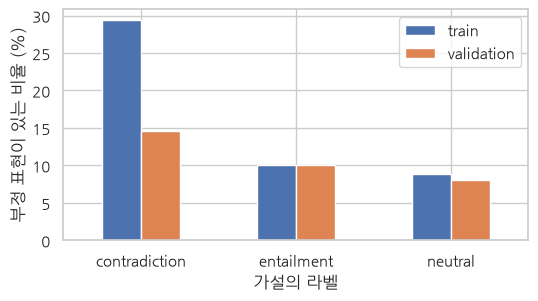

In [18]:
ax = (table * 100).plot.bar(figsize=(6, 3), rot=0)
ax.set_xlabel('가설의 라벨')
ax.set_ylabel('부정 표현이 있는 비율 (%)')
plt.savefig('plots/klue-negation.png', dpi=150, bbox_inches='tight')


'부정이면 모순'이라는 규칙을 시험한다.

- `normalize='index'`: 행마다 합이 1이 되도록 나눈다(10강의 `crosstab`).

모순은 어느 분할에서나 전체의 3분의 1쯤이다. 전제를 읽지 않고 찍으면 훈련 세트에서는 61.5%가 맞고, 검증 세트에서는 44.6%로 떨어진다. 18·19강의 분류기도 이런 것을 배울 수 있다.

In [19]:
for df in [train, valid]:
    share = pd.crosstab(df['neg'], df['name'], normalize='index')
    print(share.loc[True].round(3).to_dict())


{'contradiction': 0.615, 'entailment': 0.211, 'neutral': 0.173}
{'contradiction': 0.446, 'entailment': 0.306, 'neutral': 0.248}


## 6. 실습: 3i4K

서울말 화자 세 명이 짧은 발화를 일곱 범주로 나눈 데이터셋이다. 분할별 행의 수를 찍고, 라벨 6(억양에 달린 발화)을 읽는다. '누구 와요'는 억양에 따라 설명 의문(who), 판정 의문(someone), 진술로 읽힌다. 글자에는 억양이 없다.

In [20]:
k3 = load_dataset('wicho/kor_3i4k')
print({s: d.num_rows for s, d in k3.items()})
t3 = k3['train'].to_pandas()
print(t3.loc[t3['label'] == 6, 'text'].head(4).tolist())


{'train': 55134, 'test': 6121}
['누구 와요', '누가 절 찾아요', '겨울의 꽃샘추위도 다 가고 잘 지내세요', '잘 있었어']


위 다섯 범주를 보였다. 두 분할의 비율이 거의 같다(나머지 둘도 2.8, 1.8로 같다). 비율을 맞추어 나눈 듯하다. KLUE-NLI는 일부러 다르게 구성했다. 나누는 방법도 데이터셋마다 다르다.

In [21]:
n3 = k3['train'].features['label'].int2str
share3 = {s: k3[s].to_pandas()['label'].value_counts(normalize=True)
          for s in k3}
print((pd.DataFrame(share3).rename(index=n3) * 100).round(1).head(5))


                                train  test
label                                      
statement                        29.9  29.9
question                         29.2  29.2
command                          21.2  21.2
fragment                          9.8   9.8
intonation-dependent utterance    5.4   5.3


## 출처 적기

Park, Sungjoon et al. (2021). KLUE: Korean Language Understanding Evaluation. arXiv:2105.09680.
HuggingFace Hub `klue/klue`, 설정 `nli`, 분할 `train`, `validation`, 커밋 `349481e`. CC BY-SA 4.0.

저장소 이름, 설정, 커밋, 부정 표현의 정의(`NEG`), 패키지 버전이 이 노트북에 있다. `string_storage` 한 줄까지 있어야 다른 사람도 같은 수를 얻는다.